In [23]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
import os
import joblib

In [24]:
df = fetch_california_housing(as_frame=True).frame

In [25]:
capped = (df["MedHouseVal"] >= 5).sum()
print(capped, capped / len(df) * 100)

992 4.8062015503875966


In [26]:
corr = df.corr()
print(corr["MedHouseVal"].sort_values(ascending=False))

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


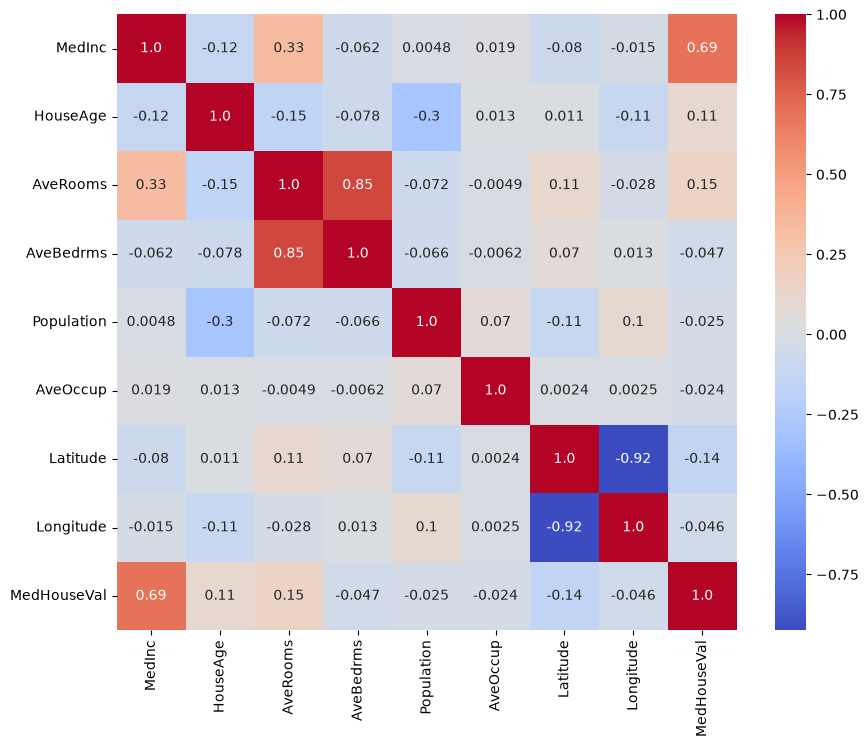

In [27]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2", cmap="coolwarm")
plt.show()

In [28]:
df[["AveRooms", "AveBedrms", "AveOccup", "Population"]].describe()

,AveRooms,AveBedrms,AveOccup,Population
count,20640.000000,20640.000000,20640.000000,20640.000000
mean,5.429000,1.096675,3.070655,1425.476744
std,2.474173,0.473911,10.386050,1132.462122
min,0.846154,0.333333,0.692308,3.000000
25%,4.440716,1.006079,2.429741,787.000000
50%,5.229129,1.048780,2.818116,1166.000000
75%,6.052381,1.099526,3.282261,1725.000000
max,141.909091,34.066667,1243.333333,35682.000000


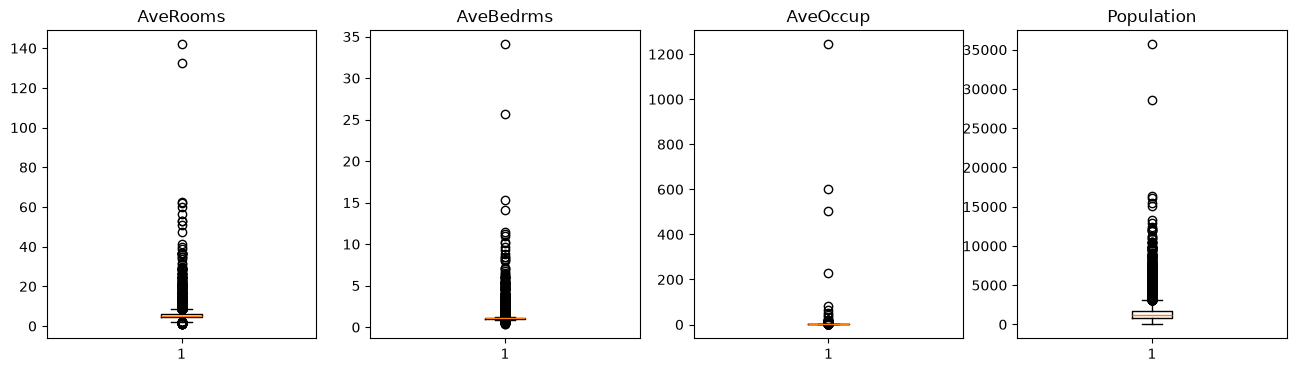

In [29]:
fig, axes = plt.subplots(1, 4, figsize= (16, 4))
for ax, col in zip(axes, ["AveRooms", "AveBedrms", "AveOccup", "Population"]):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.show()

In [30]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_test.shape, X_test.shape)

(4128, 8) (4128, 8)


In [31]:
def evaluate(name, model, X_test, y_test):
    preds = model.predict(X_test)
    mae =mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    print(f"{name}: MAE:{mae:.3f} RMSE={rmse:.3f} R2={r2:.3f}")

In [32]:
lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate("LinearRegression", lr, X_test , y_test)

LinearRegression: MAE:0.533 RMSE=0.746 R2=0.576


In [33]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
evaluate("RandomForest", rf, X_test, y_test)

RandomForest: MAE:0.328 RMSE=0.506 R2=0.804


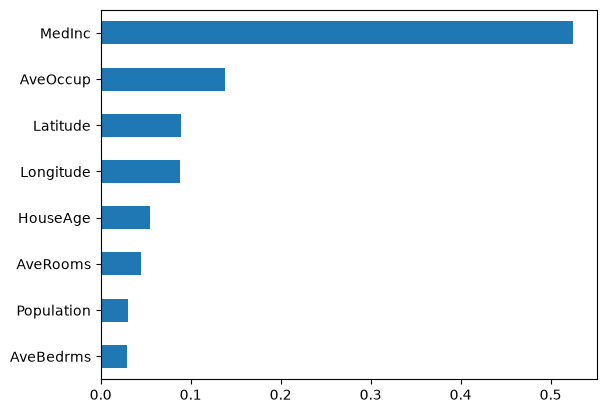

MedInc      0.524967
AveOccup    0.138382
Latitude    0.089002
dtype: float64

In [34]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances.sort_values().plot(kind="barh")
plt.show()
importances.sort_values(ascending=False).head(3)

## Model Improvement

In [35]:
print("Train R2:", rf.score(X_train, y_train))
print("Test R2:", rf.score(X_test, y_test))
      

Train R2: 0.9735550864844676
Test R2: 0.8042619569485195


In [36]:
scores = cross_val_score(rf, X_train, y_train, cv=5, scoring="r2", n_jobs=-1)
print(scores)
print("Mean:", scores.mean(), "Std:", scores.std())

[0.80955081 0.79426632 0.80839408 0.80479704 0.80534832]
Mean: 0.8044713128844272 Std: 0.005407522937836317


In [37]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
}
grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': None, 'n_estimators': 200}
0.8013352480166406


In [38]:
best_rf = grid.best_estimator_
evaluate("TunedRandomForest", best_rf, X_test, y_test)

TunedRandomForest: MAE:0.327 RMSE=0.505 R2=0.806


In [39]:
os.makedirs("../models", exist_ok=True)
joblib.dump(best_rf, "../models/rf_model.joblib" , compress=3)

['../models/rf_model.joblib']

In [40]:
loaded = joblib.load("../models/rf_model.joblib")
evaluate("LoadedModel", loaded, X_test, y_test)

LoadedModel: MAE:0.327 RMSE=0.505 R2=0.806
